# (AI-Scientific Image Forgery)
- **Kaggle Competition Data Ingestion and EDA Notebook**
  - Log into Kaggle
  - Go to setttings
  - locate and create new kaggle API key


# Research:
  - feature based and block based algorithms
  - feature based: SIFT and SURF algorithms


---


## Masks
-  Copy-Move Forgery Detection:(Localization and Classification)
- We use the mask to detect the localization of the forgery, after all saying an image is forged doesn't help unless we can point out where the forgery happens.
- The mask is the ground truth telling the model where the copy-move occurred.


**Pasted regions share:**

1. similar local descriptors

2. similar noise patterns

3. similar frequency/texture structure

4. unnatural symmetry with another region in the image

***The model learns:***

> “Pixels that look very similar to another area AND match the mask are copy-moved.”

*Without a mask, the model has no idea which pixels are forged, so it cannot learn these patterns.*
The goal is to train a model to detect and predict a mask that highlights the suspicious areas.


---
**KEY POINT**
>Normally we train a model to detect fake or real classes. This is not enough and training given only labels does not help identify the localized patterns, generates bias within classification, and trains global level clues instead of pixel level differences

---

Image Encoder:
  Encoder functions:
(Extracting the meaning of the image)

    - Detect edges, textures, patterns
    - Compress spatial resolution (downsample)
    - Increase channel depth (richer features)
    - Capture what is in the image (content)
DINOv2 encoder is a vision transformer encoder.

Image Decoder:
  Decoder functions:
(constructing a pixel-level prediction from abstract features)

    - Increase resolution
    - Produce dense pixel-by-pixel predictions
    - Output segmentation masks or heatmaps
    - Return information to original image size

Encoder learns what the image is, Decoder learns where it is.

---

## Segmenation models:
  - "which pixel belongs to which class?"
  - this model will output the forgery mask, a 0 pixel for original and 1 for forged regions.
  - encoder -> decoder -> mask output.
  - Types of encoders, CNN encoder, Transformer encoder, hybrid architectures.
  - CNN architectures are good and identifying local patterns.
  - Vision Transformers, good for global attention. helps identify long range relationship.
  - We can use a combination of Vision Transformer encoder and CNN decoder to combine the strengths and gather precision on local and global regions.

### ViT (Vision Transformer)
  - Looks at the entire image at once unlike a CNN architecture.
  - Tokenizes the image into patches, learns via the self attention mechanism.
  - each image patch is similar to a token in a regular transformer.
  - self attention allows the patches to identify relationships and give context awareness and spacial awareness.


### Data API


In [ ]:
#upload your kaggle.json API key from kaggle.
from google.colab import files
files.upload()

In [ ]:
#Calling Kaggle API for Competition Dataset
!mkdir -p /root/.config/kaggle
!mv kaggle.json /root/.config/kaggle

In [ ]:

!kaggle competitions download -c recodai-luc-scientific-image-forgery-detection
!unzip /content/recodai-luc-scientific-image-forgery-detection.zip

Streaming output truncated to the last 5000 lines.
  inflating: train_images/forged/20569.png  
  inflating: train_images/forged/20577.png  
  inflating: train_images/forged/20578.png  
  inflating: train_images/forged/20587.png  
  inflating: train_images/forged/20619.png  
  inflating: train_images/forged/2064.png  
  inflating: train_images/forged/20645.png  
  inflating: train_images/forged/20662.png  
  inflating: train_images/forged/20666.png  
  inflating: train_images/forged/20736.png  
  inflating: train_images/forged/20749.png  
  inflating: train_images/forged/20751.png  
  inflating: train_images/forged/20752.png  
  inflating: train_images/forged/20753.png  
  inflating: train_images/forged/20755.png  
  inflating: train_images/forged/20764.png  
  inflating: train_images/forged/20768.png  
  inflating: train_images/forged/20795.png  
  inflating: train_images/forged/20800.png  
  inflating: train_images/forged/20816.png  
  inflating: train_images/forged/20819.png  
  inf

### Library Imports

In [ ]:
#basic imports required to get started
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils
import pandas as pd
import os
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import cv2 as cv  #open cv, good place to start image process, object detection, heat maps, etc.

## Exploratory Analysis (planning phase)
- Check images
- Identify simple patterns, transformation requirements.
- Prepare and Identify a plan.




In [ ]:
#Directories:
FORGED_DIR = "/content/train_images/forged"
AUTHENTIC_DIR = "/content/train_images/authentic"
MASK_DIR = "/content/train_masks"
TEST_DIR = "/content/test_images"
SUBM_DIR = "/content/sample_submission.csv"

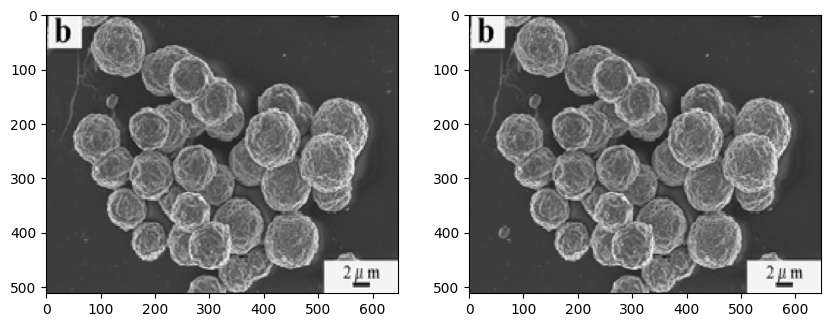

In [ ]:
#visualize
test_img = "10.png"
mask = f"{test_img.split(".")[0]}.npy"

real_img_pth = os.path.join(AUTHENTIC_DIR, test_img)
fake_img_pth = os.path.join(FORGED_DIR, test_img)

real_img = cv.imread(real_img_pth, cv.IMREAD_GRAYSCALE)
fake_img = cv.imread(fake_img_pth, cv.IMREAD_GRAYSCALE)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(real_img,cmap='gray')
ax2.imshow(fake_img,cmap='gray')


plt.show()

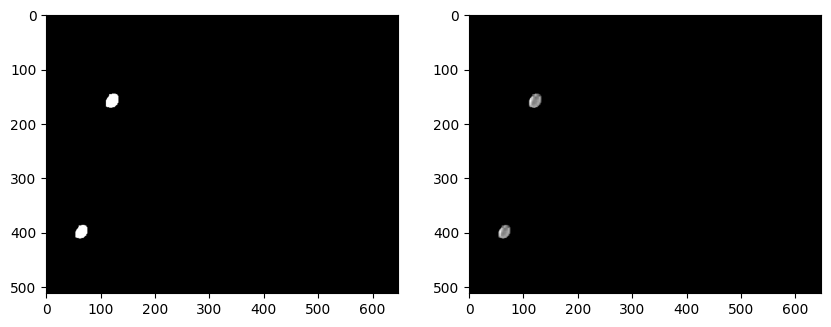

In [ ]:
img_mask_pth = os.path.join(MASK_DIR, mask)

#mask array
img_mask = np.load(img_mask_pth)
img_mask = np.squeeze(img_mask) #shrink to 2-dimensions for matplotlib since np array
fake_masked_img = cv.bitwise_and(fake_img, fake_img, mask=img_mask)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(img_mask, cmap="gray")
ax2.imshow(fake_masked_img, cmap="gray")
plt.show()


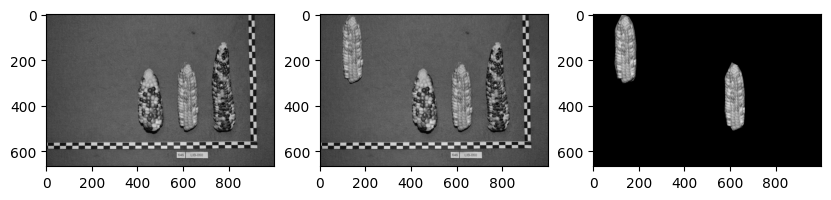

In [ ]:
from ast import For
#visualize another img
test_img = "10030.png"
mask = f"{test_img.split(".")[0]}.npy"
img_mask_pth = os.path.join(MASK_DIR, mask) #10030.npy


real_img = os.path.join(AUTHENTIC_DIR, test_img)
fake_img = os.path.join(FORGED_DIR, test_img)
mask_array = np.load(img_mask_pth).squeeze()


real_img = cv.imread(real_img, cv.IMREAD_GRAYSCALE)
fake_img = cv.imread(fake_img, cv.IMREAD_GRAYSCALE)
masked_img = cv.bitwise_and(fake_img, fake_img, mask=mask_array)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(10, 5))
ax1.imshow(real_img, cmap="gray")
ax2.imshow(fake_img, cmap="gray")
ax3.imshow(masked_img, cmap="gray")
plt.show()


In [ ]:
# Visualize OpenCV transformations

## Method v1

- Our Initial approach will take the DINOv2 ViT with additional feature based detection methods and openCv processsing to output a basic highlihted region for suspicious regions.

Detail Each step of this method:
....
...


- Following methods will include hybrid based architecture employing the ViT pre-trained encoder and CNN based decoder for more advanced localization. These will include novel approaches combining techniques of different CMF detection algorithms.

# Pytorch CustomDataset and Dataloader
Next Create Pytorch custome dataset and data loader classes for streamlined data processing.
- (data ingestion/transformations)
  - Load in the data for pytorch processing.
  - Grayscale
  - Rotations
  - etc.


In [ ]:
from logging import root
#Pytorch Device Agnostic
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")


def preprocess_image(self, image_path):
  # Read the image
  img = cv.imread(image_path, cv.IMREAD_GRAYSCALE)

  # Convert white pixels to black
  img[img == 255] = 0


  ## Random spin of the image
  angle = random.randint(0, 360)  # Generate random angle between 0 and 360 degrees
  rows, cols = img.shape[:2]
  M = cv.getRotationMatrix2D((cols/2, rows/2), angle, 1)  # Get rotation matrix
  img = cv.warpAffine(img, M, (cols, rows))  # Apply rotation

  # Optional: Normalize the image
  cleaned_image = cv.normalize(img, None, 0, 255, cv.NORM_MINMAX)

  # Convert white pixels to black again (in case normalization created new white pixels)
  cleaned_image[cleaned_image == 255] = 0

class BioMedicalData(Dataset):
  #Constructor
  def __init__(self, forged_dir, authentic_dir, mask_dir, transform=None):
    self.forged_dir = forged_dir
    self.authentic_dir = authentic_dir
    self.mask_dir = mask_dir
    self.transform = transform


    self.data = []
    #generate list of paths
    for img in os.listdir(forged_dir):
      mask = os.path.join(mask_dir, img.split('.')[0]+".npy")
      if os.path.exists(mask):
        self.data.append((os.path.join(forged_dir, img), mask))

    for img in os.listdir(authentic_dir):
        self.data.append((os.path.join(authentic_dir, img), None))

  #support len function
  def __len__(self):
    return len(self.data)


  #Support indexing
  def __getitem__(self, idx):
    #read_img
    img_path, mask_path = self.data[idx]


    #Transforms go here:

      #Grayscale

      #Noise Reduction

    return img_path, mask_path



#ADD TO THIS FOR YOUR USECASE/TASK
data_transform = transforms.Compose([
    transforms.Resize(256),            # Resize the image to 256x256 pixels
    transforms.CenterCrop(224),        # Crop the center 224x224 pixels
    transforms.ToTensor(),             # Convert the image to a PyTorch tensor
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalize the tensor, common vals.
])
train_dataset = BioMedicalData(FORGED_DIR, AUTHENTIC_DIR, MASK_DIR, data_transform)
trainloader = DataLoader(train_dataset, batch_size=4,
                        shuffle=True, num_workers=0)



In [ ]:

img_pth, mask_pth = train_dataset[0]
image = cv.imread(img_pth, cv.IMREAD_GRAYSCALE)
mask = np.load(mask_pth).squeeze()

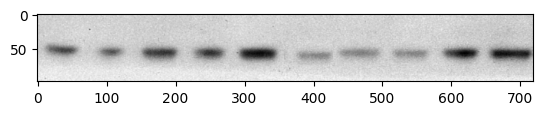

In [ ]:
plt.imshow(image, cmap = 'gray')

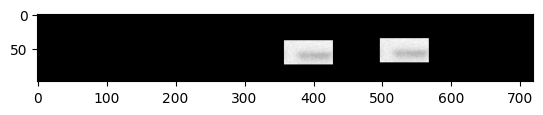

In [ ]:

masked_img = cv.bitwise_and(image, image, mask=mask)
plt.imshow(masked_img, 'gray')

In [ ]:
# Create SURF object. You can specify params here or later.
# Here I set Hessian Threshold to 400
surf = cv.xfeatures2d.SURF_create(400)
# Find keypoints and descriptors directly
kp, des = surf.detectAndCompute(image , None)
img2 = cv.drawKeypoints(image,kp,None,(255,0,0),4)
plt.imshow(img2),plt.show()



error: OpenCV(4.12.0) /io/opencv_contrib/modules/xfeatures2d/src/surf.cpp:1026: error: (-213:The function/feature is not implemented) This algorithm is patented and is excluded in this configuration; Set OPENCV_ENABLE_NONFREE CMake option and rebuild the library in function 'create'
